# Phase 2 · Legal Named Entity Recognition — Architecture-3 E-LegalFormer (frozen) + LoRA, bidirectional attention, linear token head

| | |
|---|---|
| **Codabench** | Strict Macro-F1 **0.4912** · Strict Macro-P 0.5297 · Strict Macro-R 0.4814 (rank 2 of 4 in Phase 2) |
| **Own dev / validation** | validation strict macro-F1 0.4722 (micro-F1 0.6067), best epoch 10 |
| **Backbone** | Architecture-3 E-LegalFormer, GQA (125M) |

**The task, in simple words:** find the important names in a judgment — appellant, respondent, judge, court, statute, precedent, date, … — as exact character positions with a label.

**How this notebook solves it:**
1. Split every document into words, remembering their exact character positions.
2. Read the words with the Phase-1 model, in overlapping windows (documents are longer than the model's context).
3. Give every word a tag: **B** = begins an entity, **I** = inside one, **O** = outside; the head makes sure the tag sequence is valid.
4. Turn the tags back into `[start, end, label]` spans.
5. Train on fold 1 and check on fold 2; then retrain on both folds and predict the test fold.

**What is special in this run:** **LoRA** — the Phase-1 weights stay frozen. Every layer gets a small learned *correction* added to it, `W + B·A` (rank 16), and only the two small matrices train. B starts at 0, so training starts from exactly the Phase-1 model.

*Exact setting:* LoRA, rank 16, α 32, on q/k/v/o and the SwiGLU projections.

**To run it:** Attach the tokenizer notebook's output and the Phase-1 checkpoint as Kaggle inputs, add the Hugging Face token as the Kaggle secret **`HF`**, pick a GPU (T4), then *Run All*. Paths are in the configuration cell; if a checkpoint is not found there, the notebook searches `/kaggle/input`. Test labels are never used.

Every step below starts with a short explanation: first in simple words, then how it works exactly.

# Phase 2 — L-NER — E3: LoRA on Arch-3 (E-LegalFormer)

**Method**
- Backbone: Phase-1 Arch-3 E-LegalFormer checkpoint (frozen).
- Adaptation: LoRA (rank 16) on every attention and SwiGLU projection.
- Attention: causal mask removed during fine-tuning, so every token sees left **and** right context
  (`USE_BIDIRECTIONAL = True`). Set it to `False` to compare against the causal backbone.
- Head: linear token-classification head, BIO tags (25 classes).
- Alignment: text is split into word/number/punctuation units with exact character offsets.
  Each unit is labelled from the prediction at its **last** sub-token.
- Long documents: 512-token sliding windows; overlapping predictions are averaged.
- Decoding: constrained BIO Viterbi (no `I-X` without a preceding `B-X`/`I-X`).
- Model selection: strict macro-F1 on held-out training documents, scored with the
  same exact-offset rule as Codabench.

Run all cells top to bottom. Set `DEBUG = True` in CELL 3 for a 2-minute dry run.

### CELL 1 · Imports and settings

**In simple words:** Load the Python libraries, fix the random seed (so a re-run gives the same result) and pick the GPU.

**How it works:** Seeds for `random`, NumPy and PyTorch; `DEVICE` is the GPU when one is attached.

In [1]:
# ============================================================
# CELL 1 — IMPORTS AND SETTINGS
# ============================================================

import json
import math
import random
import re
import sys
import time
import zipfile
from bisect import bisect_left
from collections import Counter
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

USE_AMP = torch.cuda.is_available()

AMP_DTYPE = (
    torch.bfloat16
    if torch.cuda.is_available() and torch.cuda.is_bf16_supported()
    else torch.float16
)

print("Device   :", device)
print("AMP      :", USE_AMP, AMP_DTYPE)
print("PyTorch  :", torch.__version__)

Device   : cuda
AMP      : True torch.bfloat16
PyTorch  : 2.11.0+cu128


### CELL 2 · Paths

**In simple words:** Where the inputs are: the tokenizer, the Phase-1 checkpoint and the output folder.

In [2]:
# ============================================================
# CELL 2 — PATHS
# ============================================================

# Phase-1 Arch-3 model (Kaggle model input)
PHASE1_MODEL_DIR = Path(
    "/kaggle/input/notebooks/ritikguptatab/proj-cap-p-1-archi-3"
)
PHASE1_CHECKPOINT_NAME = "best_model.pt"

# Phase-1 tokenizer
TOKENIZER_DIR = Path(
    "/kaggle/input/notebooks/ritikguptatab/updated-bpe-tokenizer/legal_tokenizer_v3/tokenizer/final_tokenizer"
)

# Phase-2 data
# Option A: you uploaded Phase_2_LNER as a Kaggle dataset -> set the folder here
#           (it must contain Train/ and Test/).
# Option B: leave as None -> files are downloaded from Hugging Face.
LOCAL_DATA_DIR = None
# LOCAL_DATA_DIR = Path("/kaggle/input/phase-2-lner/Phase_2_LNER")

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
HF_DATA_PREFIX = "Phase_2_LNER"

# Outputs
OUTPUT_DIR = Path("/kaggle/working/phase2_E3_lora_arch3")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_WEIGHTS_PATH = OUTPUT_DIR / "best_lora_and_head.pt"
PREDICTION_PATH = Path("/kaggle/working/prediction.json")
SUBMISSION_ZIP = Path("/kaggle/working/submission_E3_lora_arch3.zip")
SUMMARY_PATH = OUTPUT_DIR / "experiment_summary.json"

print("Model dir :", PHASE1_MODEL_DIR)
print("Tokenizer :", TOKENIZER_DIR)
print("Data      :", LOCAL_DATA_DIR or f"HF {HF_DATASET_REPO}/{HF_DATA_PREFIX}")
print("Output    :", OUTPUT_DIR)

Model dir : /kaggle/input/notebooks/ritikguptatab/proj-cap-p-1-archi-3
Tokenizer : /kaggle/input/notebooks/ritikguptatab/updated-bpe-tokenizer/legal_tokenizer_v3/tokenizer/final_tokenizer
Data      : HF Exploration-Lab/CS-781-Capstone/Phase_2_LNER
Output    : /kaggle/working/phase2_E3_lora_arch3


### CELL 3 · Experiment config

**In simple words:** Every setting of this run in one place: input paths, sizes, learning rates, epochs. To change the experiment, change only this cell.

**How it works:** The comment block at the top summarises the whole method. Mixed precision: float16 + GradScaler on T4 / P100, bfloat16 on A100. `DEBUG_MODE = True` (where present) runs a few-minute check on a small subset.

In [3]:
# ============================================================
# CELL 3 — EXPERIMENT CONFIG
# ============================================================

EXPERIMENT_NAME = "E3_LoRA_Arch3_ELegalFormer"

DEBUG = False                # True -> 6 docs, 1 epoch (pipeline check only)

# Context
USE_BIDIRECTIONAL = True     # remove causal mask during fine-tuning
WINDOW_TOKENS = 512          # tokens per window (must be <= 2048)
TRAIN_STRIDE = 256           # window step during training
PREDICT_STRIDE = 256         # window step during prediction (overlaps are averaged)

# Validation split (held-out training documents)
NUM_VAL_DOCS = 7

# LoRA
LORA_RANK = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj",
                "gate_proj", "up_proj", "down_proj"]

# Head
HEAD_DROPOUT = 0.1

# Training
EPOCHS = 12
PATIENCE = 3                 # early stop after this many epochs without val F1 gain
BATCH_SIZE = 8
GRAD_ACCUM_STEPS = 1
LORA_LR = 5e-4
HEAD_LR = 1e-3
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06
GRAD_CLIP = 1.0
PREDICT_BATCH_SIZE = 16

if DEBUG:
    EPOCHS = 1
    NUM_VAL_DOCS = 2

assert WINDOW_TOKENS <= 2048

print("Experiment       :", EXPERIMENT_NAME)
print("Bidirectional    :", USE_BIDIRECTIONAL)
print("Window / stride  :", WINDOW_TOKENS, "/", TRAIN_STRIDE)
print("LoRA r / alpha   :", LORA_RANK, "/", LORA_ALPHA)
print("Epochs / batch   :", EPOCHS, "/", BATCH_SIZE)
print("DEBUG            :", DEBUG)

Experiment       : E3_LoRA_Arch3_ELegalFormer
Bidirectional    : True
Window / stride  : 512 / 256
LoRA r / alpha   : 16 / 32
Epochs / batch   : 12 / 8
DEBUG            : False


### CELL 4 · Load Phase-2 data

**In simple words:** Download the official data of this phase from Hugging Face.

**How it works:** The dataset is gated: the token comes from the Kaggle secret `HF` (never written in the notebook). Files are cached, so a re-run does not download again.

In [4]:
# ============================================================
# CELL 4 — LOAD PHASE-2 DATA
# ============================================================

HF_TOKEN = None

if LOCAL_DATA_DIR is None:
    from huggingface_hub import hf_hub_download
    try:
        from kaggle_secrets import UserSecretsClient
        HF_TOKEN = UserSecretsClient().get_secret("HF")
    except Exception as e:
        print("No Kaggle HF secret found, trying without token:", e)


def get_data_file(relative_path):
    if LOCAL_DATA_DIR is not None:
        path = Path(LOCAL_DATA_DIR) / relative_path
        if not path.exists():
            raise FileNotFoundError(path)
        return path
    return Path(hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=f"{HF_DATA_PREFIX}/{relative_path}",
        repo_type="dataset",
        token=HF_TOKEN,
    ))


def read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


train_texts = {}
train_gold = {}

for fold in ["fold1", "fold2"]:
    texts = read_json(get_data_file(f"Train/{fold}-text.json"))
    gold = read_json(get_data_file(f"Train/{fold}-gold.json"))
    for doc_id in texts:
        train_texts[str(doc_id)] = texts[doc_id]
        train_gold[str(doc_id)] = gold.get(doc_id, [])
    print(f"{fold}: {len(texts)} documents")

with open(get_data_file("Train/labels.txt"), "r", encoding="utf-8") as f:
    ENTITY_LABELS = [line.strip() for line in f if line.strip()]

test_texts = {
    str(k): v for k, v in read_json(get_data_file("Test/fold3-text.json")).items()
}

print("Train documents :", len(train_texts))
print("Test documents  :", len(test_texts))
print("Entity labels   :", ENTITY_LABELS)

fold1: 35 documents


fold2: 35 documents


Train documents : 70
Test documents  : 35
Entity labels   : ['APP', 'RESP', 'A.COUNSEL', 'R.COUNSEL', 'JUDGE', 'WIT', 'AUTH', 'COURT', 'STAT', 'PREC', 'DATE', 'CASENO']


### CELL 5 · Data checks

**In simple words:** Check the data before using it: every entity's `(start, end)` must cut exactly its text out of the document.

**How it works:** Offsets are end-exclusive: `text[start:end] == entity text`.

In [5]:
# ============================================================
# CELL 5 — DATA CHECKS
# ============================================================
# Offsets are end-exclusive: text[start:end] == entity text.

label_counts = Counter()
offset_errors = 0
overlaps = 0

for doc_id, entities in train_gold.items():
    text = train_texts[doc_id]
    previous_end = -1
    for ent in sorted(entities, key=lambda e: (e[0], e[1])):
        start, end, label = ent[0], ent[1], ent[2]
        label_counts[label] += 1
        assert label in ENTITY_LABELS, label
        if len(ent) > 3 and text[start:end] != ent[3]:
            offset_errors += 1
        if start < previous_end:
            overlaps += 1
        previous_end = max(previous_end, end)

print("Total entities  :", sum(label_counts.values()))
print("Offset errors   :", offset_errors)
print("Overlaps        :", overlaps)
print()
for label in ENTITY_LABELS:
    print(f"  {label:10s} {label_counts[label]:5d}")

doc_lengths = [len(t) for t in train_texts.values()]
print("\nDoc length (chars): min", min(doc_lengths),
      "median", int(np.median(doc_lengths)), "max", max(doc_lengths))

Total entities  : 8393
Offset errors   : 0
Overlaps        : 0

  APP          407
  RESP         381
  A.COUNSEL    195
  R.COUNSEL    184
  JUDGE        245
  WIT          187
  AUTH        1003
  COURT       1013
  STAT        1260
  PREC        1183
  DATE        1575
  CASENO       760

Doc length (chars): min 10443 median 26620 max 114044


### CELL 6 · Load Phase-1 tokenizer

**In simple words:** Load our own Phase-1 BPE tokenizer — the same one the Phase-1 model was trained with. Any other tokenizer would give the model token ids it has never seen.

**How it works:** `tokenizer.py` from the tokenizer notebook. Long documents: only the needed part is tokenized, and every pre-token piece is BPE-encoded once and cached, which makes tokenizing thousands of judgments fast.

In [6]:
# ============================================================
# CELL 6 — LOAD PHASE-1 TOKENIZER
# ============================================================

if not TOKENIZER_DIR.exists():
    raise FileNotFoundError(TOKENIZER_DIR)

sys.path.insert(0, str(TOKENIZER_DIR))
from tokenizer import load_tokenizer

tokenizer, tokenizer_config = load_tokenizer(TOKENIZER_DIR)

SPECIAL_IDS = {
    tokenizer.pad_id,
    tokenizer.bos_id,
    tokenizer.eos_id,
}

print("Vocab size :", tokenizer.get_vocab_size())
print("PAD / UNK / BOS / EOS :",
      tokenizer.pad_id, tokenizer.unk_id, tokenizer.bos_id, tokenizer.eos_id)

Vocab size : 32004
PAD / UNK / BOS / EOS : 0 1 2 3


### CELL 7 · Units and character-safe tokenization

**In simple words:** Split the text into small *units* — a run of letters, a run of digits, or one symbol — each with its exact character position, and tokenize every unit.

**How it works:** A unit is classified from its last sub-token, so predictions map back to characters without guessing.

In [7]:
# ============================================================
# CELL 7 — UNITS AND CHARACTER-SAFE TOKENIZATION
# ============================================================
# A "unit" is a run of letters, a run of digits, or one other
# non-space character. Each unit keeps its exact (start, end)
# character offsets, so predictions map back to characters
# without any guessing.
#
# Each unit is tokenized on its own (with a leading space if it
# followed whitespace). The unit is classified from its LAST
# sub-token.

UNIT_PATTERN = re.compile(r"[^\W\d_]+|\d+|\S")

piece_cache = {}


def split_units(text):
    return [(m.start(), m.end()) for m in UNIT_PATTERN.finditer(text)]


def encode_piece(piece):
    ids = piece_cache.get(piece)
    if ids is None:
        ids = [i for i in tokenizer.encode(piece) if i not in SPECIAL_IDS]
        if len(ids) == 0:
            ids = [tokenizer.unk_id]
        piece_cache[piece] = ids
    return ids


def tokenize_units(text, units):
    token_ids = []
    unit_last_token = []
    for start, end in units:
        piece = text[start:end]
        if start > 0 and text[start - 1].isspace():
            piece = " " + piece
        token_ids.extend(encode_piece(piece))
        unit_last_token.append(len(token_ids) - 1)
    return token_ids, unit_last_token


# Quick look
sample_id = next(iter(train_texts))
sample_text = train_texts[sample_id][:300]
sample_units = split_units(sample_text)
sample_ids, _ = tokenize_units(sample_text, sample_units)

print("Original :", sample_text[:200])
print("Decoded  :", tokenizer.decode(sample_ids)[:200])
print("Units    :", len(sample_units), " tokens:", len(sample_ids),
      " (whole-text encode:", len(tokenizer.encode(sample_text)), "tokens)")

Units    : 67  tokens: 130  (whole-text encode: 130 tokens)


### CELL 8 · BIO labels, span conversion, Viterbi

**In simple words:** Entities ↔ one **B / I / O** tag per unit, and Viterbi decoding, which picks the best tag sequence that is valid.

In [8]:
# ============================================================
# CELL 8 — BIO LABELS, SPAN CONVERSION, VITERBI
# ============================================================

BIO_LABELS = ["O"]
for label in ENTITY_LABELS:
    BIO_LABELS.append("B-" + label)
    BIO_LABELS.append("I-" + label)

LABEL2ID = {label: i for i, label in enumerate(BIO_LABELS)}
NUM_BIO = len(BIO_LABELS)


def spans_to_unit_tags(units, spans):
    """Gold character spans -> one BIO tag per unit."""
    tags = ["O"] * len(units)
    unit_starts = [s for s, _ in units]
    for span in sorted(spans, key=lambda e: (e[0], e[1])):
        start, end, label = span[0], span[1], span[2]
        i = bisect_left(unit_starts, start)
        first = True
        while i < len(units) and units[i][1] <= end:
            tags[i] = ("B-" if first else "I-") + label
            first = False
            i += 1
    return tags


def unit_tags_to_spans(units, tags):
    """BIO tags per unit -> [start_char, end_char, label] spans."""
    spans = []
    current = None
    for (start, end), tag in zip(units, tags):
        if tag == "O":
            if current:
                spans.append(current)
            current = None
            continue
        prefix, label = tag.split("-", 1)
        if prefix == "B" or current is None or current[2] != label:
            if current:
                spans.append(current)
            current = [start, end, label]
        else:
            current[1] = end
    if current:
        spans.append(current)
    return spans


# Allowed transitions: I-X only after B-X or I-X; never I-X at the start
ALLOWED = np.ones((NUM_BIO, NUM_BIO), dtype=bool)   # [previous, current]
START_ALLOWED = np.ones(NUM_BIO, dtype=bool)

for j, tag in enumerate(BIO_LABELS):
    if tag.startswith("I-"):
        START_ALLOWED[j] = False
        label = tag[2:]
        for i, prev in enumerate(BIO_LABELS):
            ALLOWED[i, j] = prev in ("B-" + label, "I-" + label)

TRANSITION = np.where(ALLOWED, 0.0, -1e9)
START_SCORE = np.where(START_ALLOWED, 0.0, -1e9)


def viterbi_decode(log_probs):
    """log_probs: [num_units, NUM_BIO] -> best valid tag id per unit."""
    n = log_probs.shape[0]
    if n == 0:
        return []
    score = log_probs[0] + START_SCORE
    backpointer = np.zeros((n, NUM_BIO), dtype=np.int32)
    for t in range(1, n):
        candidates = score[:, None] + TRANSITION
        backpointer[t] = candidates.argmax(axis=0)
        score = candidates.max(axis=0) + log_probs[t]
    path = [int(score.argmax())]
    for t in range(n - 1, 0, -1):
        path.append(int(backpointer[t, path[-1]]))
    return path[::-1]


print("BIO labels:", NUM_BIO)

BIO labels: 25


### CELL 9 · Strict scorer (same rule as Codabench)

**In simple words:** The scoring rule of the leaderboard: an entity counts only if start, end **and** label all match exactly.

**How it works:** Macro-F1 = the mean of the per-label F1 over the 12 labels.

In [9]:
# ============================================================
# CELL 9 — STRICT SCORER (same rule as Codabench)
# ============================================================
# Correct only if start, end AND label all match exactly.
# Macro-F1 = mean of per-label F1 over the 12 labels.

def strict_scores(gold_by_doc, pred_by_doc):
    tp, fp, fn = Counter(), Counter(), Counter()
    for doc_id, gold_spans in gold_by_doc.items():
        gold = {(int(s[0]), int(s[1]), s[2]) for s in gold_spans}
        pred = {(int(s[0]), int(s[1]), s[2]) for s in pred_by_doc.get(doc_id, [])}
        for x in pred & gold:
            tp[x[2]] += 1
        for x in pred - gold:
            fp[x[2]] += 1
        for x in gold - pred:
            fn[x[2]] += 1

    per_label = {}
    for label in ENTITY_LABELS:
        p = tp[label] / (tp[label] + fp[label]) if tp[label] + fp[label] else 0.0
        r = tp[label] / (tp[label] + fn[label]) if tp[label] + fn[label] else 0.0
        f = 2 * p * r / (p + r) if p + r else 0.0
        per_label[label] = {"precision": p, "recall": r, "f1": f,
                            "tp": tp[label], "fp": fp[label], "fn": fn[label]}

    macro_p = float(np.mean([v["precision"] for v in per_label.values()]))
    macro_r = float(np.mean([v["recall"] for v in per_label.values()]))
    macro_f = float(np.mean([v["f1"] for v in per_label.values()]))

    total_tp, total_fp, total_fn = sum(tp.values()), sum(fp.values()), sum(fn.values())
    micro_p = total_tp / (total_tp + total_fp) if total_tp + total_fp else 0.0
    micro_r = total_tp / (total_tp + total_fn) if total_tp + total_fn else 0.0
    micro_f = 2 * micro_p * micro_r / (micro_p + micro_r) if micro_p + micro_r else 0.0

    return {"macro_f1": macro_f, "macro_precision": macro_p, "macro_recall": macro_r,
            "micro_f1": micro_f, "per_label": per_label}


def print_scores(scores, title):
    print("=" * 70)
    print(title)
    print("=" * 70)
    print(f"Strict macro-F1 : {scores['macro_f1']:.4f}")
    print(f"Macro-P / R     : {scores['macro_precision']:.4f} / {scores['macro_recall']:.4f}")
    print(f"Micro-F1        : {scores['micro_f1']:.4f}")
    print()
    print(f"{'label':10s} {'P':>6s} {'R':>6s} {'F1':>6s} {'tp':>5s} {'fp':>5s} {'fn':>5s}")
    for label, v in scores["per_label"].items():
        print(f"{label:10s} {v['precision']:6.3f} {v['recall']:6.3f} {v['f1']:6.3f} "
              f"{v['tp']:5d} {v['fp']:5d} {v['fn']:5d}")

### CELL 10 · Pipeline sanity check (no model)

**In simple words:** A check without any model: gold spans → tags → spans again. This is the best score the pipeline can reach (≈ 0.99).

**How it works:** A low number here would mean an alignment bug, not a weak model.

In [10]:
# ============================================================
# CELL 10 — PIPELINE SANITY CHECK (no model)
# ============================================================
# gold spans -> unit BIO tags -> Viterbi -> spans -> score.
# This is the best score the offset pipeline can reach.
# Expect ~0.99. A low number here means an alignment bug.

roundtrip_pred = {}

for doc_id, text in train_texts.items():
    units = split_units(text)
    tags = spans_to_unit_tags(units, train_gold[doc_id])
    one_hot = np.full((len(units), NUM_BIO), -20.0)
    one_hot[np.arange(len(units)), [LABEL2ID[t] for t in tags]] = 0.0
    path = viterbi_decode(one_hot)
    roundtrip_pred[doc_id] = unit_tags_to_spans(units, [BIO_LABELS[i] for i in path])

roundtrip = strict_scores(train_gold, roundtrip_pred)
print(f"Round-trip strict macro-F1 (upper bound): {roundtrip['macro_f1']:.4f}")
print(f"Round-trip micro recall               : "
      f"{sum(v['tp'] for v in roundtrip['per_label'].values()) / sum(label_counts.values()):.4f}")

assert roundtrip["micro_f1"] > 0.98, "Alignment problem - stop and check CELL 7/8"

Round-trip strict macro-F1 (upper bound): 0.9948
Round-trip micro recall               : 0.9927


### CELL 11 · Train / validation split and encoding

**In simple words:** Split the annotated documents into a training part and a validation part and encode them.

In [11]:
# ============================================================
# CELL 11 — TRAIN / VALIDATION SPLIT AND ENCODING
# ============================================================

def encode_document(doc_id, text, spans=None):
    units = split_units(text)
    token_ids, unit_last_token = tokenize_units(text, units)
    doc = {
        "doc_id": doc_id,
        "units": units,
        "token_ids": np.array(token_ids, dtype=np.int64),
        "unit_last_token": np.array(unit_last_token, dtype=np.int64),
    }
    if spans is not None:
        tags = spans_to_unit_tags(units, spans)
        token_labels = np.full(len(token_ids), -100, dtype=np.int64)
        token_labels[doc["unit_last_token"]] = [LABEL2ID[t] for t in tags]
        doc["token_labels"] = token_labels
    return doc


all_doc_ids = sorted(train_texts.keys())
random.Random(SEED).shuffle(all_doc_ids)

if DEBUG:
    all_doc_ids = all_doc_ids[:6]

val_doc_ids = all_doc_ids[:NUM_VAL_DOCS]
train_doc_ids = all_doc_ids[NUM_VAL_DOCS:]

start_time = time.time()
train_docs = [encode_document(d, train_texts[d], train_gold[d]) for d in train_doc_ids]
val_docs = [encode_document(d, train_texts[d], train_gold[d]) for d in val_doc_ids]
val_gold = {d: train_gold[d] for d in val_doc_ids}

train_tokens = sum(len(d["token_ids"]) for d in train_docs)
print("Train docs   :", len(train_docs), f"({train_tokens:,} tokens)")
print("Val docs     :", len(val_docs), val_doc_ids)
print("Tokens/char  :", round(train_tokens / sum(len(train_texts[d]) for d in train_doc_ids), 3))
print(f"Encoding time: {time.time() - start_time:.1f}s")

Train docs   : 63 (851,592 tokens)
Val docs     : 7 ['13618343', '94780858', '115833707', '26913217', '1161164', '154395703', '19436407']
Tokens/char  : 0.42
Encoding time: 1.1s


### CELL 12 · Sliding windows and dataloader

**In simple words:** Cut documents into overlapping windows that fit the model and batch them.

In [12]:
# ============================================================
# CELL 12 — SLIDING WINDOWS AND DATALOADER
# ============================================================

def window_starts(num_tokens, size, stride):
    if num_tokens <= size:
        return [0]
    starts = list(range(0, num_tokens - size + 1, stride))
    if starts[-1] != num_tokens - size:
        starts.append(num_tokens - size)
    return starts


train_windows = []
for doc in train_docs:
    for s in window_starts(len(doc["token_ids"]), WINDOW_TOKENS, TRAIN_STRIDE):
        ids = doc["token_ids"][s:s + WINDOW_TOKENS]
        labels = doc["token_labels"][s:s + WINDOW_TOKENS]
        train_windows.append((ids, labels))


def collate_windows(batch):
    max_len = max(len(ids) for ids, _ in batch)
    input_ids = torch.full((len(batch), max_len), tokenizer.pad_id, dtype=torch.long)
    labels = torch.full((len(batch), max_len), -100, dtype=torch.long)
    attention_mask = torch.zeros((len(batch), max_len), dtype=torch.bool)
    for i, (ids, lab) in enumerate(batch):
        input_ids[i, :len(ids)] = torch.from_numpy(ids)
        labels[i, :len(lab)] = torch.from_numpy(lab)
        attention_mask[i, :len(ids)] = True
    return input_ids, labels, attention_mask


train_loader = DataLoader(
    train_windows,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_windows,
    generator=torch.Generator().manual_seed(SEED),
)

print("Train windows :", len(train_windows))
print("Batches/epoch :", len(train_loader))

Train windows : 3298
Batches/epoch : 413


### CELL 13 · Arch-3 E-LegalFormer (encoder mode for NER)

**In simple words:** The Architecture-3 network rebuilt with the same layer names as in Phase 1 — here it reads in **both directions** (no causal mask), because a tag depends on the words before and after.

**How it works:** No KV cache, an attention mask for padded windows, and `forward()` returns hidden states instead of next-token scores.

In [13]:
# ============================================================
# CELL 13 — ARCH-3 E-LEGALFORMER (encoder mode for NER)
# ============================================================
# Same modules and parameter names as Phase 1, so the checkpoint
# loads with strict=True. Differences:
#   - no KV cache (not needed for NER)
#   - attention.causal flag (False = bidirectional)
#   - attention_mask for padded windows
#   - forward() returns hidden states, not LM logits

from dataclasses import dataclass


@dataclass
class ELegalFormerConfig:
    vocab_size: int = 32004
    max_seq_len: int = 2048
    d_model: int = 768
    n_layers: int = 16
    n_q_heads: int = 12
    n_kv_heads: int = 4
    ffn_dim: int = 2048
    dropout: float = 0.0
    rope_theta: float = 10000.0


class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps

    def forward(self, x):
        x = x * torch.rsqrt(x.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return x * self.weight


class RotaryEmbedding(nn.Module):
    def __init__(self, dim, max_seq_len, theta=10000.0):
        super().__init__()
        inv_freq = 1.0 / (theta ** (torch.arange(0, dim, 2).float() / dim))
        freqs = torch.outer(torch.arange(max_seq_len), inv_freq)
        self.register_buffer("cos", freqs.cos(), persistent=False)
        self.register_buffer("sin", freqs.sin(), persistent=False)

    def forward(self, seq_len):
        return self.cos[:seq_len], self.sin[:seq_len]


def rotate_half(x):
    x1 = x[..., :x.shape[-1] // 2]
    x2 = x[..., x.shape[-1] // 2:]
    return torch.cat((-x2, x1), dim=-1)


def apply_rope(q, k, cos, sin):
    cos = torch.cat([cos, cos], dim=-1)[None, None]
    sin = torch.cat([sin, sin], dim=-1)[None, None]
    return q * cos + rotate_half(q) * sin, k * cos + rotate_half(k) * sin


class GroupedQueryAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.n_q_heads = config.n_q_heads
        self.n_kv_heads = config.n_kv_heads
        self.head_dim = config.d_model // config.n_q_heads
        self.q_proj = nn.Linear(config.d_model, config.n_q_heads * self.head_dim, bias=False)
        self.k_proj = nn.Linear(config.d_model, config.n_kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(config.d_model, config.n_kv_heads * self.head_dim, bias=False)
        self.o_proj = nn.Linear(config.d_model, config.d_model, bias=False)
        self.causal = True

    def forward(self, x, cos, sin, attention_mask=None):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_q_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)
        q, k = apply_rope(q, k, cos, sin)

        repeat = self.n_q_heads // self.n_kv_heads
        k = k.repeat_interleave(repeat, dim=1)
        v = v.repeat_interleave(repeat, dim=1)

        if self.causal:
            # right padding is safe: real tokens never look right
            out = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            mask = None if attention_mask is None else attention_mask[:, None, None, :]
            out = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)

        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.o_proj(out)


class SwiGLU(nn.Module):
    def __init__(self, d_model, ffn_dim):
        super().__init__()
        self.gate_proj = nn.Linear(d_model, ffn_dim, bias=False)
        self.up_proj = nn.Linear(d_model, ffn_dim, bias=False)
        self.down_proj = nn.Linear(ffn_dim, d_model, bias=False)

    def forward(self, x):
        return self.down_proj(F.silu(self.gate_proj(x)) * self.up_proj(x))


class ELegalFormerBlock(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.attn_norm = RMSNorm(config.d_model)
        self.attention = GroupedQueryAttention(config)
        self.ffn_norm = RMSNorm(config.d_model)
        self.ffn = SwiGLU(config.d_model, config.ffn_dim)

    def forward(self, x, cos, sin, attention_mask=None):
        x = x + self.attention(self.attn_norm(x), cos, sin, attention_mask)
        x = x + self.ffn(self.ffn_norm(x))
        return x


class ELegalFormer(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.token_embedding = nn.Embedding(config.vocab_size, config.d_model)
        self.rope = RotaryEmbedding(config.d_model // config.n_q_heads,
                                    config.max_seq_len, config.rope_theta)
        self.layers = nn.ModuleList([ELegalFormerBlock(config) for _ in range(config.n_layers)])
        self.final_norm = RMSNorm(config.d_model)
        self.lm_head = nn.Linear(config.d_model, config.vocab_size, bias=False)
        self.lm_head.weight = self.token_embedding.weight   # tied, as in Phase 1

    def set_bidirectional(self, bidirectional):
        for layer in self.layers:
            layer.attention.causal = not bidirectional

    def forward(self, input_ids, attention_mask=None):
        T = input_ids.size(1)
        x = self.token_embedding(input_ids)
        cos, sin = self.rope(T)
        cos = cos.to(dtype=x.dtype)
        sin = sin.to(dtype=x.dtype)
        for layer in self.layers:
            x = layer(x, cos, sin, attention_mask)
        return self.final_norm(x)


print("Architecture defined.")

Architecture defined.


### CELL 14 · Load Phase-1 checkpoint

**In simple words:** Load the trained Phase-1 Architecture-3 weights into the network.

**How it works:** `strict=True`: every weight name and shape must match.

In [14]:
# ============================================================
# CELL 14 — LOAD PHASE-1 CHECKPOINT
# ============================================================

candidates = sorted(PHASE1_MODEL_DIR.rglob(PHASE1_CHECKPOINT_NAME))
if not candidates:
    raise FileNotFoundError(
        f"{PHASE1_CHECKPOINT_NAME} not found under {PHASE1_MODEL_DIR}"
    )
PHASE1_CHECKPOINT = candidates[0]

checkpoint = torch.load(PHASE1_CHECKPOINT, map_location="cpu", weights_only=False)

config_dict = checkpoint.get("config", {})
CONFIG = ELegalFormerConfig(**{
    k: v for k, v in config_dict.items()
    if k in ELegalFormerConfig.__dataclass_fields__
})

state_dict = {
    k.replace("_orig_mod.", ""): v
    for k, v in checkpoint["model_state_dict"].items()
}

backbone = ELegalFormer(CONFIG)
backbone.load_state_dict(state_dict, strict=True)
backbone = backbone.to(device)

print("Checkpoint :", PHASE1_CHECKPOINT)
print("Step       :", checkpoint.get("step", "unknown"))
print("Val loss   :", checkpoint.get("best_val_loss", "unknown"))
print("Config     :", CONFIG)

del checkpoint, state_dict

Checkpoint : /kaggle/input/notebooks/ritikguptatab/proj-cap-p-1-archi-3/model3_checkpoints/best_model.pt
Step       : 8000
Val loss   : 1.2227919439558077
Config     : ELegalFormerConfig(vocab_size=32004, max_seq_len=2048, d_model=768, n_layers=16, n_q_heads=12, n_kv_heads=4, ffn_dim=2048, dropout=0.0, rope_theta=10000.0)


### CELL 15 · Check: does the loaded model still know legal text?

**In simple words:** A quick health check: the loaded model should still predict legal text well (low perplexity).

**How it works:** A huge value (> 1,000) would mean the tokenizer and the checkpoint do not match.

In [15]:
# ============================================================
# CELL 15 — CHECK: DOES THE LOADED MODEL STILL KNOW LEGAL TEXT?
# ============================================================
# Next-token perplexity of the Phase-1 model (causal mode) on a
# training window built with OUR unit tokenization.
# Should be close to your Phase-1 validation perplexity.
# A huge value (> 1000) means tokenizer/checkpoint mismatch.

backbone.set_bidirectional(False)
backbone.eval()

check_ids = torch.tensor(train_docs[0]["token_ids"][:WINDOW_TOKENS])[None].to(device)

with torch.no_grad(), torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=USE_AMP):
    hidden = backbone(check_ids)
    lm_logits = backbone.lm_head(hidden).float()

lm_loss = F.cross_entropy(lm_logits[0, :-1], check_ids[0, 1:])
print(f"Phase-1 LM perplexity on a train window: {math.exp(lm_loss.item()):.2f}")

Phase-1 LM perplexity on a train window: 8.70


### CELL 16 · LoRA

**In simple words:** LoRA: instead of changing a big weight matrix, learn a small correction next to it.

**How it works:** `W·x + (α/r)·B·A·x`, with A: r × in and B: out × r; B starts at 0, so the model starts unchanged.

In [16]:
# ============================================================
# CELL 16 — LoRA
# ============================================================
# W x  +  (alpha / r) * B A x      (A: r x in, B: out x r, B starts at 0)

class LoRALinear(nn.Module):
    def __init__(self, base, rank, alpha, dropout):
        super().__init__()
        self.base = base
        self.base.weight.requires_grad = False
        self.lora_A = nn.Parameter(torch.empty(rank, base.in_features))
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, rank))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        self.scaling = alpha / rank
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        lora = self.dropout(x) @ self.lora_A.t() @ self.lora_B.t()
        return self.base(x) + lora * self.scaling


# 1) freeze the whole Phase-1 model
for p in backbone.parameters():
    p.requires_grad = False

# 2) wrap the target projections in every layer
lora_count = 0
for layer in backbone.layers:
    for parent in [layer.attention, layer.ffn]:
        for name in LORA_TARGETS:
            if hasattr(parent, name):
                base = getattr(parent, name)
                setattr(parent, name, LoRALinear(base, LORA_RANK, LORA_ALPHA, LORA_DROPOUT))
                lora_count += 1

backbone = backbone.to(device)
backbone.set_bidirectional(USE_BIDIRECTIONAL)

print("LoRA modules inserted:", lora_count)

LoRA modules inserted: 112


### CELL 17 · NER model (backbone + token-classification head)

**In simple words:** Backbone + a small linear layer that gives tag scores for every unit.

In [17]:
# ============================================================
# CELL 17 — NER MODEL (backbone + token-classification head)
# ============================================================

class LegalNERModel(nn.Module):
    def __init__(self, backbone, num_labels, dropout):
        super().__init__()
        self.backbone = backbone
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(backbone.config.d_model, num_labels)
        nn.init.normal_(self.classifier.weight, std=0.02)
        nn.init.zeros_(self.classifier.bias)

    def forward(self, input_ids, attention_mask=None):
        hidden = self.backbone(input_ids, attention_mask)
        return self.classifier(self.dropout(hidden))


model = LegalNERModel(backbone, NUM_BIO, HEAD_DROPOUT).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
lora_params = sum(p.numel() for n, p in model.named_parameters() if "lora_" in n)
head_params = sum(p.numel() for n, p in model.named_parameters() if "classifier" in n)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,} ({100 * trainable_params / total_params:.2f}%)")
print(f"  LoRA               : {lora_params:,}")
print(f"  Head               : {head_params:,}")

Total parameters     : 128,760,345
Trainable parameters : 3,492,633 (2.71%)
  LoRA               : 3,473,408
  Head               : 19,225


### CELL 18 · Optimizer and schedule

**In simple words:** Set up the optimizer (AdamW) and the learning-rate schedule: a short warm-up, then the rate slowly goes down.

**How it works:** Only the weights that should train are given to the optimizer; the new head gets a larger learning rate than the backbone.

In [18]:
# ============================================================
# CELL 18 — OPTIMIZER AND SCHEDULE
# ============================================================

lora_parameters = [p for n, p in model.named_parameters() if p.requires_grad and "lora_" in n]
head_parameters = [p for n, p in model.named_parameters() if p.requires_grad and "classifier" in n]

optimizer = torch.optim.AdamW(
    [
        {"params": lora_parameters, "lr": LORA_LR, "weight_decay": WEIGHT_DECAY},
        {"params": head_parameters, "lr": HEAD_LR, "weight_decay": 0.0},
    ],
    betas=(0.9, 0.98),
    eps=1e-8,
)

STEPS_PER_EPOCH = math.ceil(len(train_loader) / GRAD_ACCUM_STEPS)
TOTAL_STEPS = STEPS_PER_EPOCH * EPOCHS
WARMUP_STEPS = max(1, int(TOTAL_STEPS * WARMUP_RATIO))


def lr_lambda(step):
    if step < WARMUP_STEPS:
        return (step + 1) / WARMUP_STEPS
    progress = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
    return 0.5 * (1 + math.cos(math.pi * min(1.0, progress)))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

scaler = torch.amp.GradScaler("cuda") if USE_AMP and AMP_DTYPE == torch.float16 else None

print("Steps / epoch :", STEPS_PER_EPOCH)
print("Total steps   :", TOTAL_STEPS)
print("Warmup steps  :", WARMUP_STEPS)
print("GradScaler    :", scaler is not None)

Steps / epoch : 413
Total steps   : 4956
Warmup steps  : 297
GradScaler    : False


### CELL 19 · Prediction (document -> character spans)

**In simple words:** Predict a whole document: windows → tag scores per unit (averaged where windows overlap) → Viterbi → character spans.

In [19]:
# ============================================================
# CELL 19 — PREDICTION (document -> character spans)
# ============================================================

@torch.no_grad()
def predict_unit_log_probs(model, doc):
    token_ids = doc["token_ids"]
    n = len(token_ids)
    log_prob_sum = np.zeros((n, NUM_BIO), dtype=np.float32)
    counts = np.zeros(n, dtype=np.float32)

    starts = window_starts(n, WINDOW_TOKENS, PREDICT_STRIDE)
    for b in range(0, len(starts), PREDICT_BATCH_SIZE):
        batch_starts = starts[b:b + PREDICT_BATCH_SIZE]
        # every window of one document has the same length -> no padding
        batch = np.stack([token_ids[s:s + WINDOW_TOKENS] for s in batch_starts])
        x = torch.from_numpy(batch).to(device)
        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=USE_AMP):
            logits = model(x)
        log_probs = F.log_softmax(logits.float(), dim=-1).cpu().numpy()
        for row, s in enumerate(batch_starts):
            length = log_probs.shape[1]
            log_prob_sum[s:s + length] += log_probs[row]
            counts[s:s + length] += 1

    token_log_probs = log_prob_sum / counts[:, None]
    return token_log_probs[doc["unit_last_token"]]


def predict_document_spans(model, doc):
    unit_log_probs = predict_unit_log_probs(model, doc)
    path = viterbi_decode(unit_log_probs)
    tags = [BIO_LABELS[i] for i in path]
    return unit_tags_to_spans(doc["units"], tags)


def evaluate(model, docs, gold_by_doc):
    model.eval()
    preds = {doc["doc_id"]: predict_document_spans(model, doc) for doc in docs}
    return strict_scores(gold_by_doc, preds), preds


print("Prediction functions ready.")

Prediction functions ready.


### CELL 20 · Training

**In simple words:** Train, check on validation after every epoch, and keep the best weights.

In [20]:
# ============================================================
# CELL 20 — TRAINING
# ============================================================

def trainable_state(model):
    return {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}


history = []
best_f1 = -1.0
best_epoch = 0
epochs_without_gain = 0
global_step = 0

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

training_start = time.time()

for epoch in range(1, EPOCHS + 1):

    model.train()
    epoch_start = time.time()
    running_loss = 0.0
    optimizer.zero_grad(set_to_none=True)

    for step, (input_ids, labels, attention_mask) in enumerate(train_loader, start=1):

        input_ids = input_ids.to(device)
        labels = labels.to(device)
        attention_mask = attention_mask.to(device)

        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=USE_AMP):
            logits = model(input_ids, attention_mask)

        loss = F.cross_entropy(
            logits.float().view(-1, NUM_BIO),
            labels.view(-1),
            ignore_index=-100,
        )

        if scaler is not None:
            scaler.scale(loss / GRAD_ACCUM_STEPS).backward()
        else:
            (loss / GRAD_ACCUM_STEPS).backward()

        running_loss += loss.item()

        if step % GRAD_ACCUM_STEPS == 0 or step == len(train_loader):
            if scaler is not None:
                scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad], GRAD_CLIP
            )
            if scaler is not None:
                scaler.step(optimizer)
                scaler.update()
            else:
                optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            global_step += 1

        if step % 50 == 0:
            print(f"  epoch {epoch} step {step}/{len(train_loader)} "
                  f"loss {running_loss / step:.4f} lr {scheduler.get_last_lr()[0]:.2e}")

    train_loss = running_loss / len(train_loader)
    epoch_time = time.time() - epoch_start

    val_scores, _ = evaluate(model, val_docs, val_gold)
    val_f1 = val_scores["macro_f1"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_macro_f1": val_f1,
        "val_micro_f1": val_scores["micro_f1"],
        "epoch_seconds": epoch_time,
    })

    print(f"Epoch {epoch:2d} | train loss {train_loss:.4f} | "
          f"val macro-F1 {val_f1:.4f} | val micro-F1 {val_scores['micro_f1']:.4f} | "
          f"{epoch_time:.0f}s")

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_epoch = epoch
        epochs_without_gain = 0
        torch.save(trainable_state(model), BEST_WEIGHTS_PATH)
        print(f"  ✓ new best saved -> {BEST_WEIGHTS_PATH}")
    else:
        epochs_without_gain += 1
        if epochs_without_gain >= PATIENCE:
            print(f"Early stopping (no gain for {PATIENCE} epochs).")
            break

training_minutes = (time.time() - training_start) / 60
peak_memory_gb = torch.cuda.max_memory_allocated() / 1e9 if torch.cuda.is_available() else 0.0

print()
print(f"Best val macro-F1 : {best_f1:.4f} (epoch {best_epoch})")
print(f"Training time     : {training_minutes:.1f} min")
print(f"Peak GPU memory   : {peak_memory_gb:.2f} GB")

  epoch 1 step 50/413 loss 2.2326 lr 8.59e-05
  epoch 1 step 100/413 loss 1.2512 lr 1.70e-04
  epoch 1 step 150/413 loss 0.8819 lr 2.54e-04
  epoch 1 step 200/413 loss 0.6889 lr 3.38e-04
  epoch 1 step 250/413 loss 0.5689 lr 4.23e-04
  epoch 1 step 300/413 loss 0.4898 lr 5.00e-04
  epoch 1 step 350/413 loss 0.4328 lr 5.00e-04
  epoch 1 step 400/413 loss 0.3885 lr 4.99e-04
Epoch  1 | train loss 0.3786 | val macro-F1 0.3934 | val micro-F1 0.5735 | 512s
  ✓ new best saved -> /kaggle/working/phase2_E3_lora_arch3/best_lora_and_head.pt
  epoch 2 step 50/413 loss 0.0581 lr 4.98e-04
  epoch 2 step 100/413 loss 0.0587 lr 4.97e-04
  epoch 2 step 150/413 loss 0.0585 lr 4.96e-04
  epoch 2 step 200/413 loss 0.0586 lr 4.94e-04
  epoch 2 step 250/413 loss 0.0553 lr 4.92e-04
  epoch 2 step 300/413 loss 0.0532 lr 4.90e-04
  epoch 2 step 350/413 loss 0.0519 lr 4.88e-04
  epoch 2 step 400/413 loss 0.0510 lr 4.85e-04
Epoch  2 | train loss 0.0505 | val macro-F1 0.3865 | val micro-F1 0.5284 | 517s
  epoch 3

### CELL 21 · Training curves

**In simple words:** Plot the training loss and the validation score per epoch.

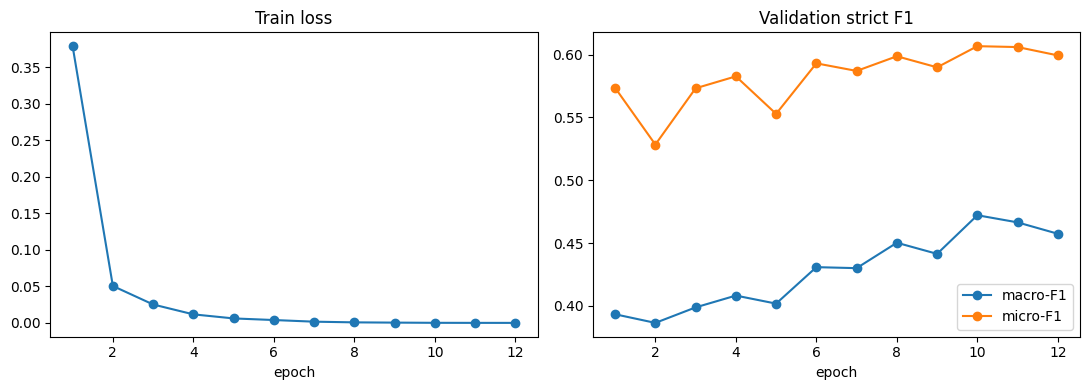

In [21]:
# ============================================================
# CELL 21 — TRAINING CURVES
# ============================================================

import matplotlib.pyplot as plt

epochs_axis = [h["epoch"] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs_axis, [h["train_loss"] for h in history], marker="o")
axes[0].set_title("Train loss")
axes[0].set_xlabel("epoch")
axes[1].plot(epochs_axis, [h["val_macro_f1"] for h in history], marker="o", label="macro-F1")
axes[1].plot(epochs_axis, [h["val_micro_f1"] for h in history], marker="o", label="micro-F1")
axes[1].set_title("Validation strict F1")
axes[1].set_xlabel("epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=120)
plt.show()

### CELL 22 · Best model: validation report + error analysis

**In simple words:** Scores of the best epoch per label, and the most common kinds of error.

In [22]:
# ============================================================
# CELL 22 — BEST MODEL: VALIDATION REPORT + ERROR ANALYSIS
# ============================================================

best_state = torch.load(BEST_WEIGHTS_PATH, map_location=device)
model.load_state_dict(best_state, strict=False)
model.eval()

val_scores, val_preds = evaluate(model, val_docs, val_gold)
print_scores(val_scores, f"VALIDATION — best epoch {best_epoch}")

# Error types (for the report)
errors = Counter()
for doc_id, gold_spans in val_gold.items():
    gold = {(s[0], s[1], s[2]) for s in gold_spans}
    pred = {tuple(s) for s in val_preds[doc_id]}
    for ps, pe, pl in pred - gold:
        overlapping = [g for g in gold if g[0] < pe and ps < g[1]]
        if not overlapping:
            errors["spurious (no gold overlap)"] += 1
        elif any(g[0] == ps and g[1] == pe for g in overlapping):
            errors["wrong label, exact span"] += 1
        elif any(g[2] == pl for g in overlapping):
            errors["boundary error, right label"] += 1
        else:
            errors["boundary + label error"] += 1
    for gs, ge, gl in gold - pred:
        if not any(p[0] < ge and gs < p[1] for p in pred):
            errors["missed (no prediction overlap)"] += 1

print("\nError analysis (validation):")
for k, v in errors.most_common():
    print(f"  {k:32s} {v}")

VALIDATION — best epoch 10
Strict macro-F1 : 0.4722
Macro-P / R     : 0.5093 / 0.4607
Micro-F1        : 0.6067

label           P      R     F1    tp    fp    fn
APP         0.278  0.147  0.192    10    26    58
RESP        0.478  0.212  0.293    11    12    41
A.COUNSEL   0.520  0.310  0.388    13    12    29
R.COUNSEL   0.383  0.562  0.456    18    29    14
JUDGE       0.578  0.605  0.591    26    19    17
WIT         0.000  0.000  0.000     0     3     0
AUTH        0.559  0.311  0.400    19    15    42
COURT       0.900  0.940  0.920    63     7     4
STAT        0.696  0.701  0.699    94    41    40
PREC        0.303  0.272  0.287    43    99   115
DATE        0.969  0.954  0.961   249     8    12
CASENO      0.448  0.514  0.479    74    91    70

Error analysis (validation):
  missed (no prediction overlap)   204
  boundary error, right label      194
  spurious (no gold overlap)       99
  wrong label, exact span          38
  boundary + label error           31


### CELL 23 · Predict test set

**In simple words:** Predict the entities of every test document with the best model.

In [23]:
# ============================================================
# CELL 23 — PREDICT TEST SET
# ============================================================

test_start = time.time()
test_predictions = {}

for i, (doc_id, text) in enumerate(test_texts.items(), start=1):
    doc = encode_document(doc_id, text)
    spans = predict_document_spans(model, doc)
    test_predictions[doc_id] = [[int(s), int(e), label] for s, e, label in spans]
    if i % 10 == 0 or i == len(test_texts):
        print(f"  {i}/{len(test_texts)} documents")

inference_minutes = (time.time() - test_start) / 60
print(f"Test inference time: {inference_minutes:.1f} min")
print("Predicted entities :", sum(len(v) for v in test_predictions.values()))
print("Label distribution :", Counter(s[2] for v in test_predictions.values() for s in v))

  10/35 documents
  20/35 documents
  30/35 documents
  35/35 documents
Test inference time: 2.1 min
Predicted entities : 3837
Label distribution : Counter({'STAT': 766, 'DATE': 739, 'PREC': 666, 'COURT': 563, 'CASENO': 335, 'AUTH': 323, 'JUDGE': 100, 'R.COUNSEL': 96, 'A.COUNSEL': 94, 'APP': 60, 'RESP': 58, 'WIT': 37})


### CELL 24 · Validate and write prediction.json + zip

**In simple words:** Check the prediction format and write `prediction.json` + `submission.zip`.

In [24]:
# ============================================================
# CELL 24 — VALIDATE AND WRITE prediction.json + ZIP
# ============================================================

assert set(test_predictions) == set(test_texts), "Test IDs do not match"

for doc_id, spans in test_predictions.items():
    text = test_texts[doc_id]
    previous_end = -1
    for start, end, label in sorted(spans):
        assert isinstance(start, int) and isinstance(end, int)
        assert 0 <= start < end <= len(text), (doc_id, start, end)
        assert label in ENTITY_LABELS, label
        assert text[start:end] == text[start:end].strip(), (doc_id, start, end)
        assert start >= previous_end, f"overlap in {doc_id}"
        previous_end = end

with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(test_predictions, f, ensure_ascii=False)

with zipfile.ZipFile(SUBMISSION_ZIP, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write(PREDICTION_PATH, arcname="prediction.json")

with zipfile.ZipFile(SUBMISSION_ZIP) as zf:
    assert zf.namelist() == ["prediction.json"]

first_doc = next(iter(test_predictions))
print("✓ prediction.json :", PREDICTION_PATH)
print("✓ submission zip  :", SUBMISSION_ZIP)
print("Example:", first_doc, [
    s + [test_texts[first_doc][s[0]:s[1]]] for s in test_predictions[first_doc][:5]
])

✓ prediction.json : /kaggle/working/prediction.json
✓ submission zip  : /kaggle/working/submission_E3_lora_arch3.zip


### CELL 25 · Save experiment summary (for the report)

**In simple words:** Save the numbers of this run for the report.

In [25]:
# ============================================================
# CELL 25 — SAVE EXPERIMENT SUMMARY (for the report)
# ============================================================

summary = {
    "experiment": EXPERIMENT_NAME,
    "phase1_checkpoint": str(PHASE1_CHECKPOINT),
    "method": "LoRA on all attention + SwiGLU projections, frozen backbone, linear BIO head",
    "bidirectional_attention": USE_BIDIRECTIONAL,
    "window_tokens": WINDOW_TOKENS,
    "train_stride": TRAIN_STRIDE,
    "predict_stride": PREDICT_STRIDE,
    "lora_rank": LORA_RANK,
    "lora_alpha": LORA_ALPHA,
    "lora_targets": LORA_TARGETS,
    "epochs_run": len(history),
    "best_epoch": best_epoch,
    "total_params": total_params,
    "trainable_params": trainable_params,
    "lora_params": lora_params,
    "head_params": head_params,
    "train_docs": len(train_docs),
    "val_docs": val_doc_ids,
    "training_minutes": training_minutes,
    "inference_minutes_test": inference_minutes,
    "peak_gpu_memory_gb": peak_memory_gb,
    "roundtrip_upper_bound_macro_f1": roundtrip["macro_f1"],
    "val_macro_f1": val_scores["macro_f1"],
    "val_macro_precision": val_scores["macro_precision"],
    "val_macro_recall": val_scores["macro_recall"],
    "val_micro_f1": val_scores["micro_f1"],
    "val_per_label_f1": {k: v["f1"] for k, v in val_scores["per_label"].items()},
    "val_error_analysis": dict(errors),
    "history": history,
}

with open(SUMMARY_PATH, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("Summary saved:", SUMMARY_PATH)
print(json.dumps({k: summary[k] for k in
                  ["val_macro_f1", "trainable_params", "training_minutes", "peak_gpu_memory_gb"]},
                 indent=2))

Summary saved: /kaggle/working/phase2_E3_lora_arch3/experiment_summary.json
{
  "val_macro_f1": 0.47215998645723484,
  "trainable_params": 3492633,
  "training_minutes": 107.39141736427943,
  "peak_gpu_memory_gb": 5.79153408
}
